# 제4장 추가 실습 노트북

장 폴더에서 위에서 아래로 실행하세요. 프로그램 원본과 동일한 코드를 `%run`으로 실행합니다. 데이터 출처·가정·학습 범위는 각 절의 README를 함께 확인하세요. CSV는 내려받은 고정 입력이며 외부 API·GPU가 필요하지 않습니다.

In [1]:
import sys
from pathlib import Path
print("Python:", sys.version.split()[0])
print("Working folder:", Path.cwd())

Python: 3.12.14
Working folder: /workspace/scratch/52b332c0a516/textbook_repo/textbook_extensions/20261016/ch04


## 4.11 결측 분포와 범주별 관측 수 탐색

결측률과 범주별 표본 수를 구분하고 삭제·대치 전에 자료 상태를 기록한다.

왼쪽 분모는 전체 행 수다. 오른쪽 C0 등은 긴 범주명의 표시용 코드이며 의미는 JSON의 contract_codes에서 확인한다.

주의: 값의 부재 원인은 표만으로 알 수 없다. 결측률이 낮다고 무작위 결측이라고 단정하지 않는다.

In [2]:
%run sec_11_missingness.py

{
  "rows": 1200,
  "duplicate_rows": 0,
  "missing_fraction": {
    "total_charge": 0.016666666666666666,
    "monthly_charge": 0.016666666666666666,
    "support": 0.016666666666666666,
    "customer_id": 0.0,
    "age": 0.0,
    "tenure": 0.0,
    "contract": 0.0,
    "internet": 0.0,
    "ebilling": 0.0,
    "churn": 0.0
  },
  "contract_codes": {
    "C0": "monthly",
    "C1": "one_year",
    "C2": "two_year"
  }
}


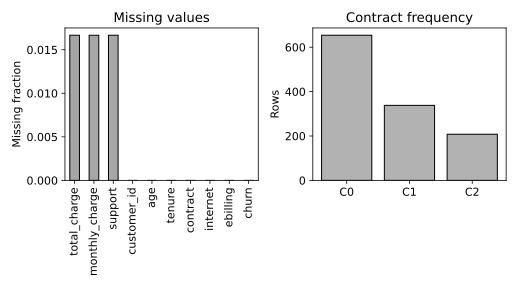

In [3]:
from IPython.display import SVG, display
display(SVG(filename="results/missingness.svg"))

### 확인 과제

결측이 있는 열과 완전한 열을 구분하고, 행 삭제로 제외될 고객 유형이 무엇인지 적는다.

## 4.12 산점도·상관행렬·이상값 플래그 비교

단변량 이상값 후보, 두 변수의 관계, 여러 변수의 선형 상관을 함께 확인한다.

누적 요금과 이용 기간의 상관은 계산 방식에서 생길 수도 있다. 상관행렬은 열별 완전 관측 쌍으로 계산되므로 모든 칸의 표본 수가 같다고 가정하지 않는다.

주의: IQR 경계는 오류 판정기가 아니다. 훈련 전처리에 쓸 경계라면 훈련 자료에서만 추정해야 한다.

In [4]:
%run sec_12_correlation_outlier.py

{
  "iqr_flags": {
    "age": 0,
    "tenure": 0,
    "monthly_charge": 9,
    "total_charge": 5
  },
  "pairwise_corr_tenure_total": 0.8197286745425285
}


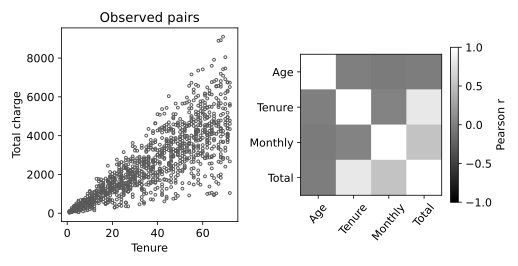

In [5]:
from IPython.display import SVG, display
display(SVG(filename="results/correlation_outlier.svg"))

### 확인 과제

플래그가 붙은 행을 찾아 합법적 극단값인지 입력 오류인지 구분할 추가 근거를 제시한다.